In [17]:
import pandas as pd

# 1. Membaca file dataset CSV
df = pd.read_csv("data_getaran_dummy.csv")

# Menampilkan 5 baris pertama data
print("=== 5 DATA PERTAMA ===")
display(df.head(5))

=== 5 DATA PERTAMA ===


,Percobaan,Percepatan dasar (g),Percepatan struktur (g),Perpindahan (mm)
0,1,0.10,0.15,0.8
1,2,0.25,0.40,2.4
2,3,0.50,0.75,4.7
3,4,0.80,1.10,6.2
4,5,0.95,1.35,7.5


In [24]:
# 2. Fungsi penentuan kelas berdasarkan perpindahan (displacement)
def klasifikasi(displacement):
    if displacement <= 2.0:
        return "Rendah"
    elif displacement <= 5.0:
        return "Sedang"
    else:
        return "Tinggi"

# Menerapkan fungsi ke dataframe untuk membuat kolom kelas baru
df["kelas"] = df["Perpindahan (mm)"].apply(klasifikasi)

# 2.1 Menentukan Kolom Fitur (X) dan Target (y)
fitur = ["Percepatan dasar (g)", "Percepatan struktur (g)"]
X = df[fitur]
y = df["kelas"]

print("Preprocessing dan pelabelan selesai!")
display(df.tail(12)) # Menampilkan beberapa data terakhir beserta kelasnya

Preprocessing dan pelabelan selesai!


,Percobaan,Percepatan dasar (g),Percepatan struktur (g),Perpindahan (mm),kelas
0,1,0.10,0.15,0.8,Rendah
1,2,0.25,0.40,2.4,Sedang
2,3,0.50,0.75,4.7,Sedang
3,4,0.80,1.10,6.2,Tinggi
4,5,0.95,1.35,7.5,Tinggi


In [25]:
from sklearn.tree import DecisionTreeClassifier

#3 Inisialisasi model Decision Tree dengan kriteria Gini
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=42
)

#3.1 Melatih model dengan data fitur (X) dan target (y)
model.fit(X, y)

print("Model Decision Tree berhasil dilatih!")

Model Decision Tree berhasil dilatih!


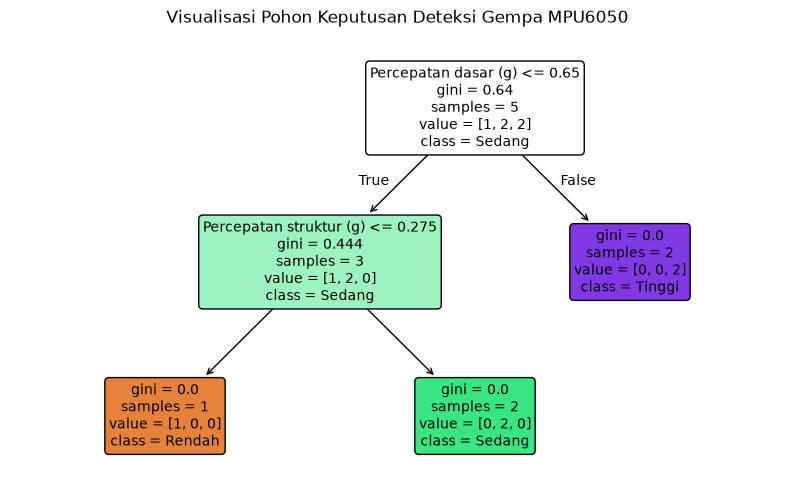

In [26]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

#4 Membuat visualisasi pohon keputusan
plt.figure(figsize=(10, 6))
plot_tree(
    model, 
    feature_names=fitur, 
    class_names=model.classes_, 
    filled=True, 
    rounded=True,
    fontsize=10
)
plt.title("Visualisasi Pohon Keputusan Deteksi Gempa MPU6050", fontsize=12)
plt.show()

In [23]:
# Input manual data dari simulasi sensor MPU
print("\n=== SIMULASI INPUT DATA SENSOR MPU ===")
acc_dasar = float(input("Masukkan Percepatan Dasar (g): "))
acc_struktur = float(input("Masukkan Percepatan Struktur (g): "))

# Validasi input tidak boleh negatif
if acc_dasar < 0 or acc_struktur < 0:
    raise ValueError("Nilai percepatan tidak boleh negatif!")

# Membungkus input ke dalam DataFrame untuk diprediksi model
data_baru = pd.DataFrame(
    [[acc_dasar, acc_struktur]],
    columns=fitur
)

# Melakukan prediksi kelas
hasil_prediksi = model.predict(data_baru)[0]

# Menampilkan hasil akhir
print("\n===== HASIL PREDIKSI STATUS GEMPA =====")
print(f"Percepatan Dasar    : {acc_dasar} g")
print(f"Percepatan Struktur : {acc_struktur} g")
print(f"Klasifikasi Status  : {hasil_prediksi.upper()}")


=== SIMULASI INPUT DATA SENSOR MPU ===


Masukkan Percepatan Dasar (g):  0.2
Masukkan Percepatan Struktur (g):  0.2



===== HASIL PREDIKSI STATUS GEMPA =====
Percepatan Dasar    : 0.2 g
Percepatan Struktur : 0.2 g
Klasifikasi Status  : GEMPA RENDAH
